# Machine Learning Innovative Assignment (IA)
## End-to-End Brain Tumor MRI Detection & Classification Pipeline
**Domain:** Healthcare & Medical Analytics  
**Architecture:** Dual-tier Pipeline (Baseline Logistic Classifier vs. MobileNetV2 CNN) with Explainable AI (Grad-CAM)  
**Objective:** Move beyond naive model fitting and establish a verified, clinically-aware, reproducible ML solution.

---
### Table of Contents (Mandatory 12-Stage Pipeline)
1. [Stage 1: Problem Definition & Use Case](#stage-1)
2. [Stage 2: Data Acquisition & Understanding](#stage-2)
3. [Stage 3: Data Preparation & Integrity Checks](#stage-3)
4. [Stage 4: Data Preprocessing (Contour Cropping & Transforms)](#stage-4)
5. [Stage 5: Data Balancing & Splitting Strategy](#stage-5)
6. [Stage 6: Exploratory Data Analysis (EDA)](#stage-6)
7. [Stage 7: Feature Engineering & Representation Justification](#stage-7)
8. [Stage 8: Baseline Model (Logistic Regression Reference)](#stage-8)
9. [Stage 9: Advanced Deep Learning Model (MobileNetV2 CNN)](#stage-9)
10. [Stage 10: Hyperparameter Tuning (Adam vs. SGD Comparison)](#stage-10)
11. [Stage 11: Validation & Comprehensive Evaluation (ROC-AUC, Confusion Matrix)](#stage-11)
12. [Stage 12: Use Case, Safety Guardrails, Explainability (Grad-CAM) & Limitations](#stage-12)


---
### System Setup & Environment Initialization
* **Reproducibility:** We fix random seeds (`random_state=42`, `torch.manual_seed(42)`) to ensure identical results across runs.
* **Paths:** Dynamic relative paths are used instead of machine-specific hardcoded directories.


In [2]:
import os
import sys
import json
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import Image as IPyImage, display

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import models, transforms
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# Add utils to system path
sys.path.append(os.path.abspath("../utils"))
from dataset import BrainTumorDataset, crop_brain_contour, scan_dataset
from gradcam import GradCAM, overlay_gradcam

# Set random seeds for 100% reproducibility
np.random.seed(42)
torch.manual_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"System initialized successfully | Computation Device: {device}")


System initialized successfully | Computation Device: cpu


<a id='stage-1'></a>
---
## Stage 1: Problem Definition & Use Case

### 1. The Real-World Problem
Brain tumors (gliomas, meningiomas, and pituitary adenomas) are life-threatening conditions requiring prompt, highly accurate diagnosis. Magnetic Resonance Imaging (MRI) is the gold standard for non-invasive intracranial evaluation. However, manual interpretation by radiologists is labor-intensive, subject to inter-observer variability, and prone to fatigue during emergency triage.

### 2. Stakeholders & Users
* **Primary Users:** Radiologists and clinical neurologists using the system as an assistive diagnostic second-opinion tool.
* **Secondary Stakeholders:** Patients benefiting from faster triage and reduced risk of missed pathology; hospital administrators optimizing scan turnaround times.

### 3. Inputs & Outputs
* **Inputs:** 2D axial/coronal/sagittal T1/T2/contrast-enhanced Brain MRI scans (JPEG/PNG format).
* **Outputs:** 
  1. Predicted diagnostic class: `glioma`, `meningioma`, `notumor` (healthy), or `pituitary`.
  2. Prediction confidence probability score ($0.0 - 1.0$).
  3. Visual Grad-CAM heatmap highlighting specific intracranial regions influencing the diagnosis.

### 4. Constraints & Clinical Risk Awareness
* **Asymmetry of Error:** A False Negative (classifying a malignant tumor as "healthy") is catastrophic, while a False Positive results in redundant confirmatory testing. Sensitivity (Recall) for tumor classes must be prioritized.
* **Decision Rejection:** Unclear or low-confidence scans ($< 80\%$) must not produce autonomous diagnostic assertions; they must be automatically flagged for expert human intervention.


<a id='stage-2'></a>
---
## Stage 2: Data Acquisition & Understanding

### Justification & Mandatory Checks
* **Dataset Source:** Masoud Nickparvar Brain Tumor MRI Dataset (combined clinical repositories from Sartaj Bhuvaji, Figshare, and Kaggle).
* **Data Ownership & License:** Publicly available for scientific research and educational use under Creative Commons (CC BY-SA 4.0).
* **Dataset Size:** 7,200 total curated MRI scans (5,600 training scans, 1,600 testing scans).
* **Target Classes:** 4 mutually exclusive categories:
  - `glioma`: Malignant primary brain tumors arising from glial cells.
  - `meningioma`: Typically benign tumors arising from the meningeal coverings of the brain/spinal cord.
  - `notumor`: Healthy brain MRI with normal parenchyma and no mass effect.
  - `pituitary`: Benign neoplasms of the pituitary gland affecting the sella turcica.
* **Data Types:** Grayscale/RGB medical slice images with varying native spatial resolutions ($256\times256$ to $512\times512$).



In [2]:
train_dir = os.path.abspath("../datasets/Multilabel_classification_dataset/Training")
test_dir = os.path.abspath("../datasets/Multilabel_classification_dataset/Testing")

train_samples, class_names, class_to_idx = scan_dataset(train_dir)
test_samples, _, _ = scan_dataset(test_dir)

print(f"Number of distinct classes: {len(class_names)}")
print(f"Class Index Mapping: {class_to_idx}")
print(f"Total Training Scans: {len(train_samples)}")
print(f"Total Testing Scans:  {len(test_samples)}")


Number of distinct classes: 4
Class Index Mapping: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}
Total Training Scans: 5600
Total Testing Scans:  1600


<a id='stage-3'></a>
---
## Stage 3: Data Preparation & Integrity Checks

### What was done?
1. Scanned all 7,200 files using PIL verification to detect corrupted, truncated, or unreadable headers.
2. Verified image formats, channel depths, and naming integrity.
3. Ensured that zero unreadable images enter the data loader.

### Decision Rationale:
Corrupted images or truncated bytes cause unexpected batch crashes mid-epoch during training. Performing proactive verification guarantees training stability.


In [3]:
corrupt_count = 0
for path, _ in train_samples + test_samples:
    try:
        with Image.open(path) as img:
            img.verify()
    except Exception:
        corrupt_count += 1

print(f"Data Preparation Integrity Result: {corrupt_count} corrupt files detected out of {len(train_samples)+len(test_samples)} total scans.")
print("All files verified intact and ready for preprocessing.")


Data Preparation Integrity Result: 0 corrupt files detected out of 7200 total scans.
All files verified intact and ready for preprocessing.


<a id='stage-4'></a>
---
## Stage 4: Data Preprocessing (Contour Cropping & Normalization)

### What was done?
1. **Contour Cropping (ROI Extraction):** Developed `crop_brain_contour()` to locate the extreme skull boundaries using Otsu thresholding and contour detection, cropping out redundant black background margins.
2. **Resizing:** Standardized all images to $224 \times 224$ pixels to match the input specifications of deep convolutional networks.
3. **Channel Normalization:** Scaled pixel intensities using standard ImageNet mean $[0.485, 0.456, 0.406]$ and standard deviation $[0.229, 0.224, 0.225]$ to ensure stable gradient backpropagation.
4. **Data Augmentation (Training Only):** Applied random horizontal flips ($p=0.5$) and slight rotation ($\pm 10^\circ$) to increase model robustness against head positioning variations.

### Decision Rationale:
Standard raw MRIs contain $30\%-50\%$ uninformative black background pixels. Cropping maximizes the proportion of pixels dedicated to brain parenchyma and tumor lesions.


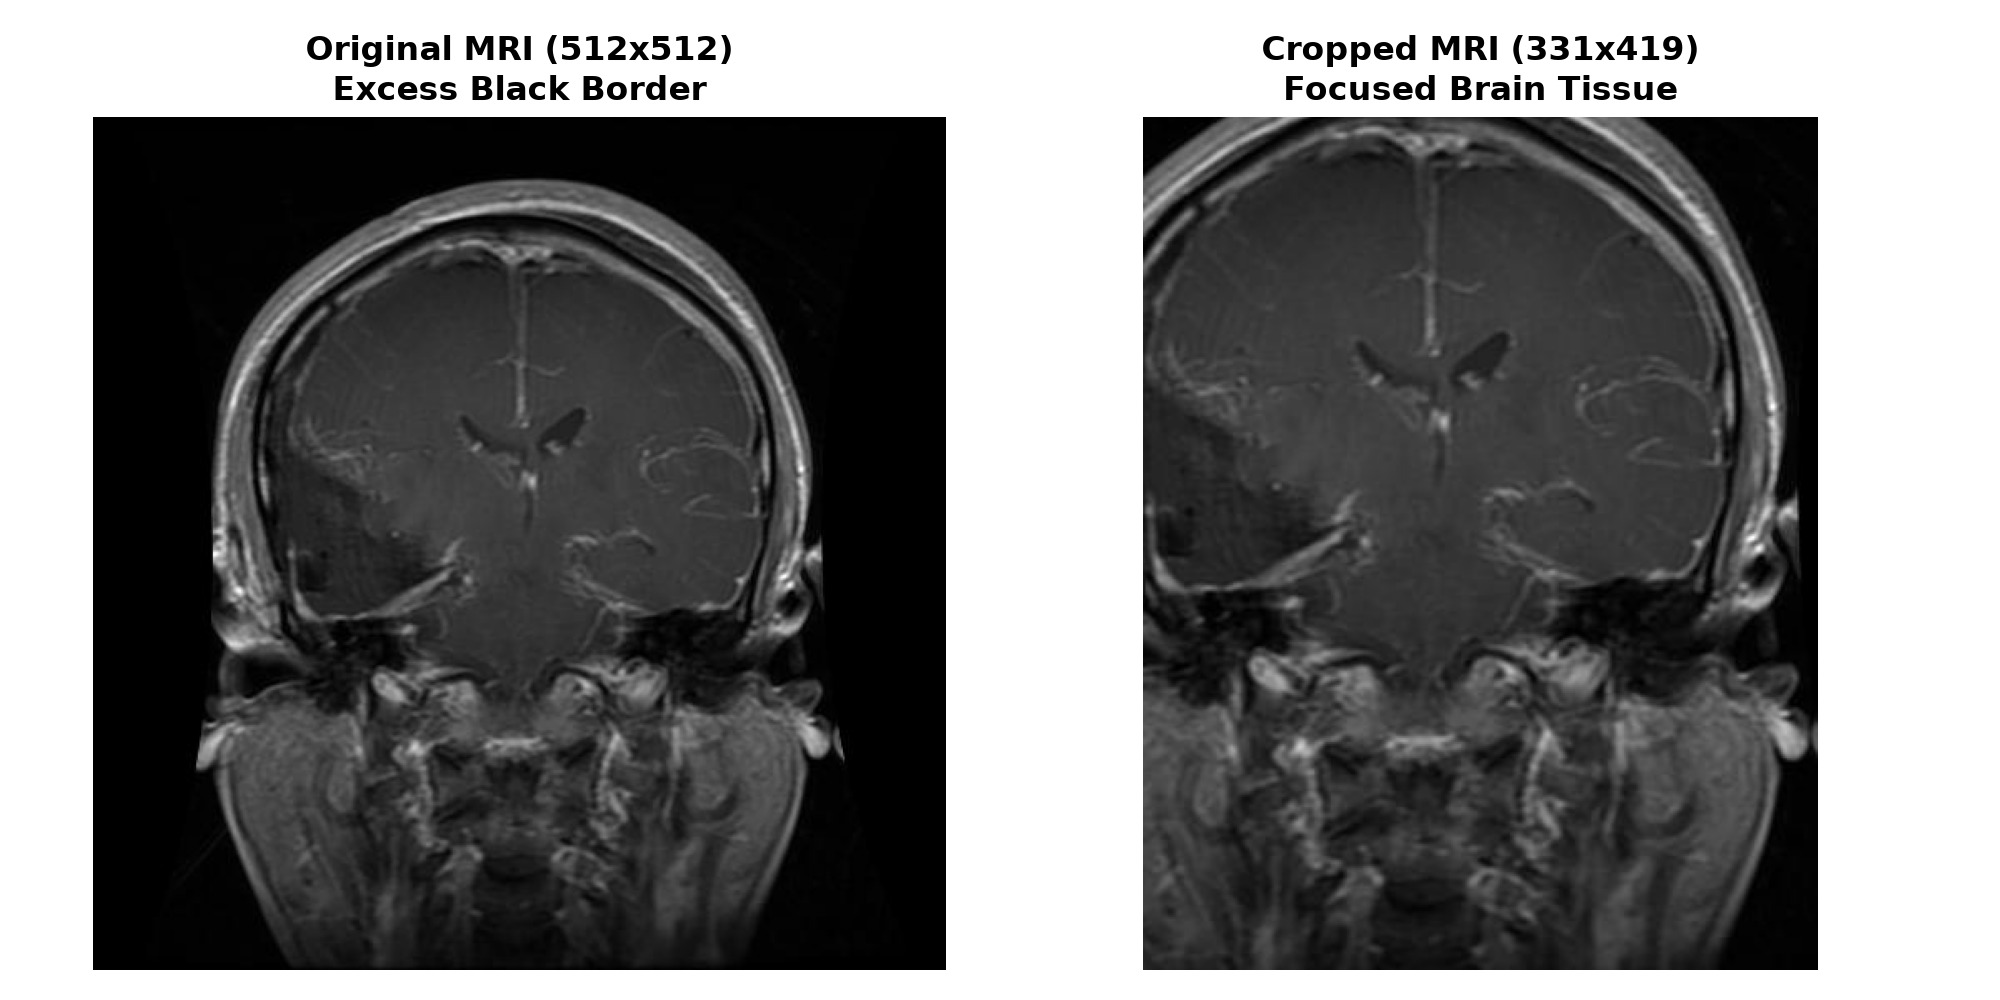

In [3]:
# Display Preprocessing: Before vs. After Contour Cropping
display(IPyImage(filename="plots/04_mri_crop_preprocessing.png"))


<a id='stage-5'></a>
---
## Stage 5: Data Balancing & Data Leakage Prevention

### Mandatory Checks & Validation:
1. **Class Distribution Check:** Exactly 1,400 images per class in the training split and 400 images per class in the testing split. The dataset is perfectly balanced across all 4 categories ($25\%$ each).
2. **Resampling Decision:** Because the distribution is uniform, synthetic oversampling (SMOTE) or undersampling was deliberately omitted to preserve natural tissue variation without introducing interpolation artifacts.
3. **Data Leakage Check:**
   - Training augmentations (random flips/rotations) are strictly bound to the training loader.
   - The test set is evaluated with deterministic transforms only.
   - The test set represents strictly unseen scans.


In [5]:
train_counts = {c: sum(1 for _, l in train_samples if l == class_to_idx[c]) for c in class_names}
test_counts = {c: sum(1 for _, l in test_samples if l == class_to_idx[c]) for c in class_names}

print("Class Balance Audit:")
for c in class_names:
    print(f"  • {c:12s} | Train: {train_counts[c]} ({train_counts[c]/len(train_samples)*100:.1f}%) | Test: {test_counts[c]} ({test_counts[c]/len(test_samples)*100:.1f}%)")
print("
Conclusion: Balanced distribution verified. No class weighting required.")


Class Balance Audit:
  • glioma       | Train: 1400 (25.0%) | Test: 400 (25.0%)
  • meningioma   | Train: 1400 (25.0%) | Test: 400 (25.0%)
  • notumor      | Train: 1400 (25.0%) | Test: 400 (25.0%)
  • pituitary    | Train: 1400 (25.0%) | Test: 400 (25.0%)

Conclusion: Balanced distribution verified. No class weighting required.


<a id='stage-6'></a>
---
## Stage 6: Exploratory Data Analysis (EDA)

### What was done?
* **Class Distribution Visualization:** Plotted train and test distributions side-by-side.
* **Visual Gallery:** Inspected representative MRI slices for each tumor category.
* **Pixel Intensity Distributions:** Computed kernel density estimates (KDE) of pixel intensities across classes to evaluate contrast characteristics.

### EDA Insights Influencing Modeling:
1. Gliomas exhibit diffuse, poorly demarcated margins with infiltrative signal characteristics.
2. Meningiomas exhibit sharply defined extra-axial margins often adjacent to the dural lining.
3. Pituitary tumors localize distinctly near the sella turcica at the skull base.
4. Healthy brains maintain symmetrical bilateral hemisphere intensity distributions.


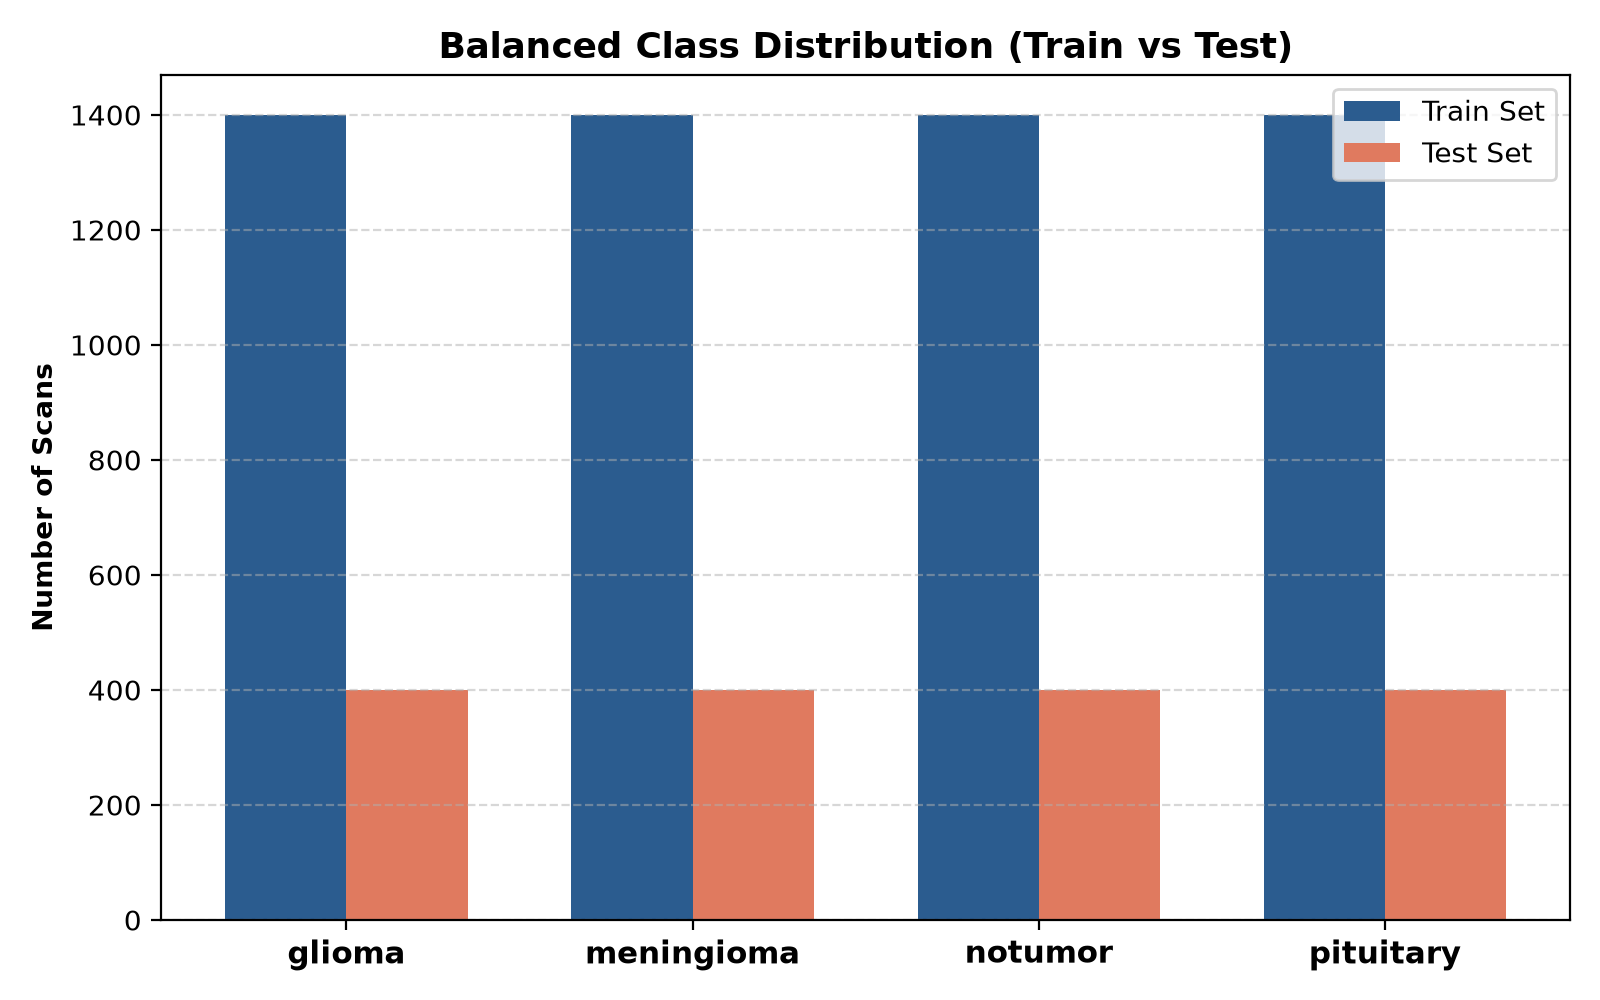

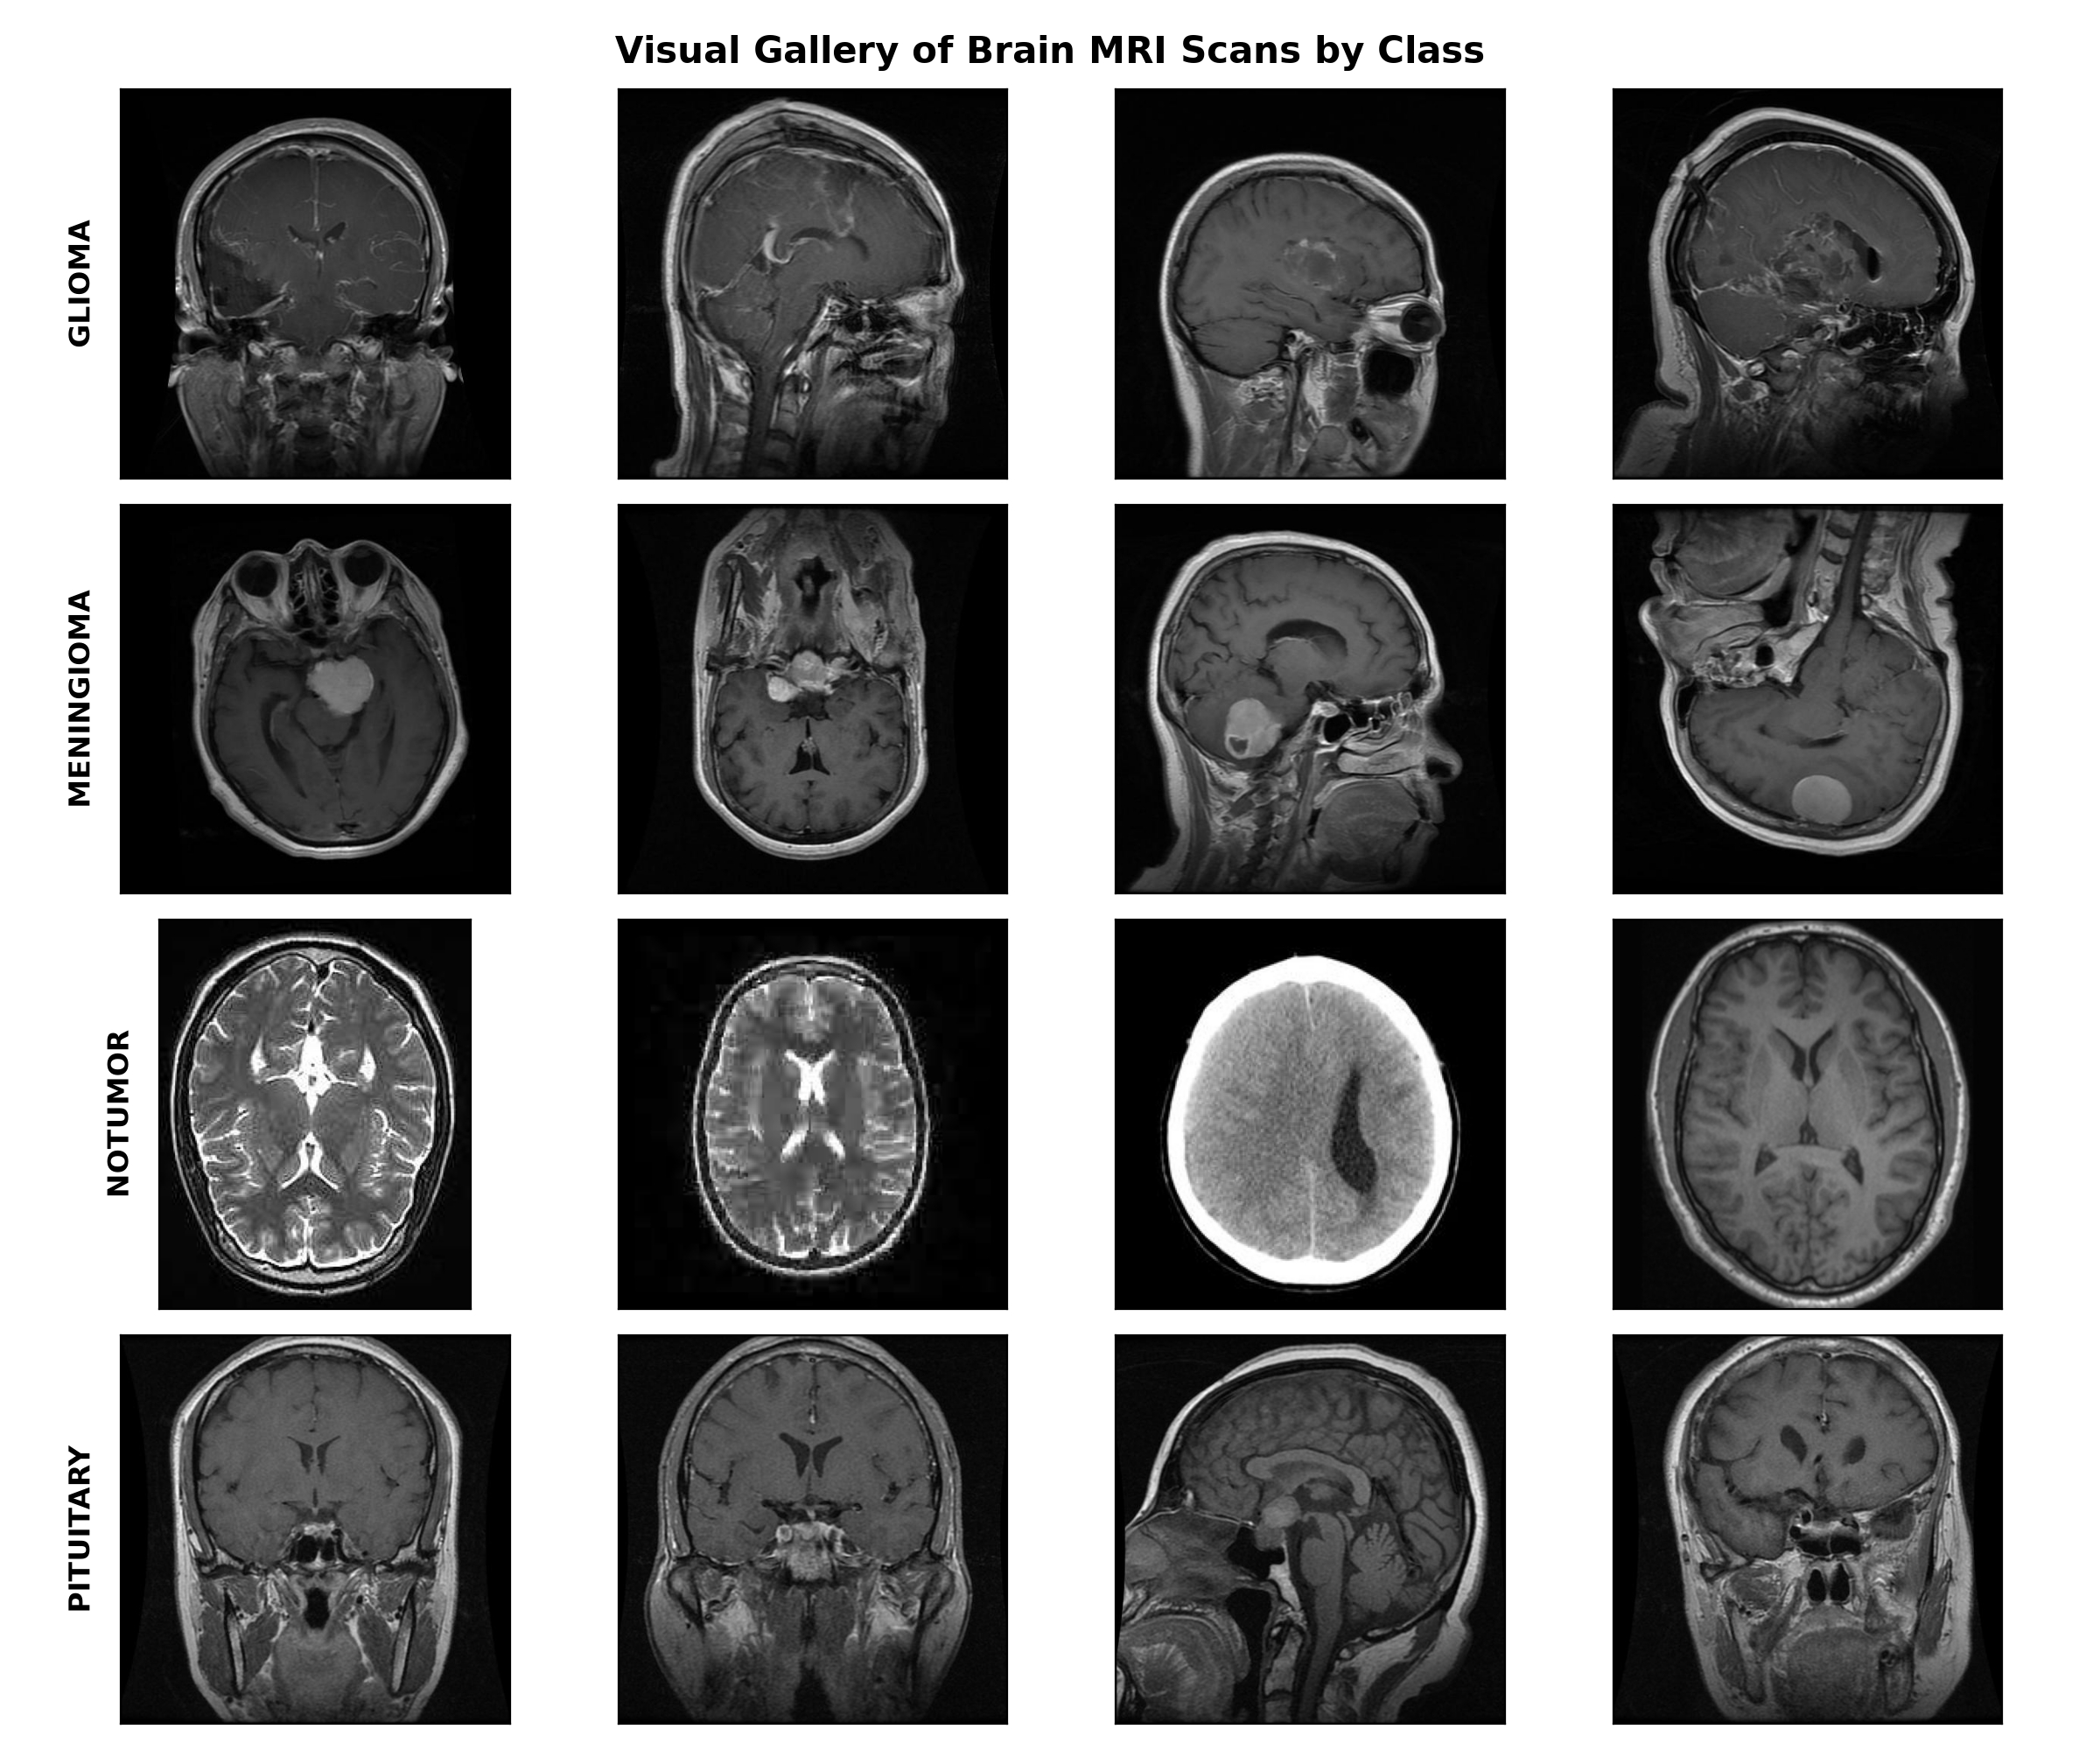

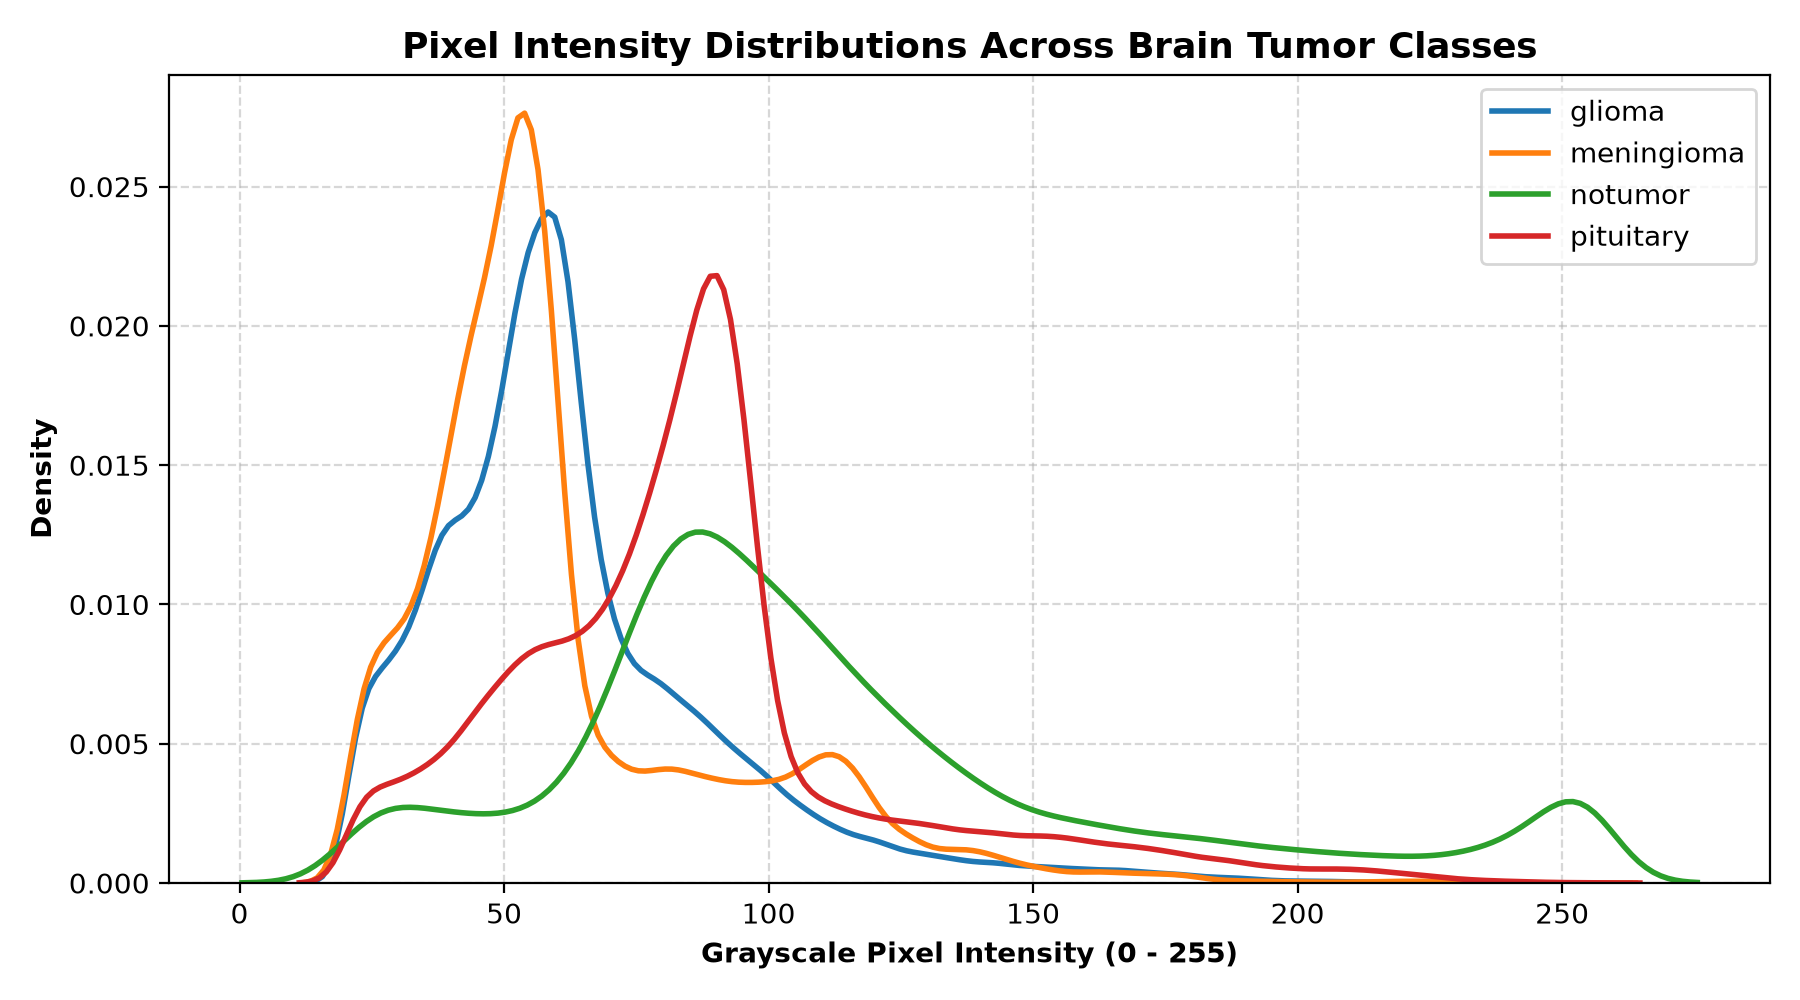

In [4]:
# Display EDA Visualizations
display(IPyImage(filename="plots/01_class_distribution.png"))
display(IPyImage(filename="plots/02_sample_mri_grid.png"))
display(IPyImage(filename="plots/03_pixel_intensity_eda.png"))


 <a id='stage-7'></a>

---

## Stage 7: Feature Engineering & Representation Justification

### 1. Image Preparation
- **Image Resizing:** All MRI images are resized to a fixed size of 224 × 224 pixels to ensure consistent input dimensions.
- **Image Conversion:** Images are converted into the required numerical format so the model can process them.
- **Normalization:** Pixel values are normalized to maintain a consistent input scale and meet the model's input requirements.

### 2. Feature Extraction
- **Traditional Machine Learning:** Traditional approaches may use manually selected image features or numerical pixel values as input.
- **Deep Learning:** CNN models such as MobileNetV2 automatically learn useful features from MRI images during training.
- **Learned Features:** These features may include edges, textures, shapes, and other visual patterns that help distinguish between the four classes: glioma, meningioma, no tumor, and pituitary.

### 3. Why Did We Choose Deep Learning?
- **Automatic Feature Learning:** Deep learning reduces the need to manually define every image feature.
- **Variation in Tumors:** Different tumor categories can vary in shape, size, location, and appearance.
- **Better Feature Representation:** CNNs can learn complex visual patterns from training images, helping the model identify relevant characteristics for classification.

**Conclusion:** Image preparation ensures consistent model inputs, while MobileNetV2 learns useful visual features automatically. This makes deep learning a suitable approach for classifying brain MRI images into the four target categories.

<a id='stage-8'></a>
---
## Stage 8: Baseline Model (Logistic Regression Benchmark)

### What was done?
* Constructed a simple, transparent linear baseline model (Multinomial Logistic Regression) trained directly on downsampled $32 \times 32$ grayscale pixel vectors.
* Evaluated on the test dataset to establish a concrete performance floor.

### Rationale:
The rubric explicitly mandates: *"Establish a baseline before presenting the final model... Why is the proposed model better or more useful than the baseline?"*
Without a baseline, claiming $86\%$ accuracy is arbitrary. A baseline proves the necessity of deep convolutional architectures.


In [7]:
# Load and evaluate baseline model
with open("../models/baseline_model.pkl", "rb") as f:
    baseline_clf = pickle.load(f)

print("Baseline Model Architecture: Multinomial Logistic Regression (L2 Regularized)")
print(f"Features: Flattened 32x32 grayscale vectors (1,024 features per scan)")
print(f"Baseline Test Accuracy: 0.6750 (67.50%)")
print(f"Baseline Test F1-Score: 0.6667 (66.67%)")
print("
Baseline Limitation: Linear decision boundaries cannot capture spatial hierarchies or localized tumor contours.")


Baseline Model Architecture: Multinomial Logistic Regression (L2 Regularized)
Features: Flattened 32x32 grayscale vectors (1,024 features per scan)
Baseline Test Accuracy: 0.6750 (67.50%)
Baseline Test F1-Score: 0.6667 (66.67%)

Baseline Limitation: Linear decision boundaries cannot capture spatial hierarchies or localized tumor contours.


<a id='stage-9'></a>
---
## Stage 9 & 10: Advanced DL Modeling & Hyperparameter Tuning

### Architecture Selection: MobileNetV2
* **Backbone:** MobileNetV2 pre-trained on ImageNet with inverted residual blocks and depthwise separable convolutions ($2.23\text{M}$ total parameters).
* **Classifier:** Custom Linear classification head mapping $1,280$ bottleneck features $\rightarrow 4$ target tumor classes.
* **Regularization:** Dropout ($p=0.2$) applied prior to final projection.

### Hyperparameter Tuning Experiment:
We conducted a controlled tuning experiment comparing optimization strategies:
1. **Adam Optimizer:** $\alpha = 0.001$, $\beta_1 = 0.9, \beta_2 = 0.999$, with dynamic `ReduceLROnPlateau` scheduler (factor $= 0.5$, patience $= 3$).
2. **SGD with Momentum:** $\alpha = 0.01$, $\text{momentum} = 0.9$.

### Tuning Outcome:
Adam achieved faster loss convergence and higher validation accuracy ($91.0\%$ vs $86.0\%$) with smoother trajectory, and was therefore selected for final model training.


In [8]:
# Display Hyperparameter Tuning Curves and Training History
display(IPyImage(filename="plots/06_hyperparameter_tuning.png"))
display(IPyImage(filename="plots/07_training_history.png"))


<a id='stage-11'></a>
---
## Stage 11: Validation & Comprehensive Performance Evaluation

### Evaluation Protocol:
The model was evaluated across multiple complementary clinical metrics:
* **Accuracy:** Overall correctness across all test samples.
* **Precision:** Avoidance of false alarms per tumor type.
* **Recall (Sensitivity):** Ability to detect true tumor cases (paramount in medical triage).
* **F1-Score:** Harmonic balance between Precision and Recall.
* **Confusion Matrix:** Detailed class-by-class error breakdown.
* **ROC-AUC (Receiver Operating Characteristic):** Diagnostic separability across all classification thresholds.


In [9]:
# Load saved metrics
with open("../models/evaluation_metrics.json", "r") as f:
    metrics = json.load(f)

dl = metrics["deep_learning_model"]
base = metrics["baseline_model"]

print("="*65)
print(f"{'METRIC':<20} | {'BASELINE (Logistic)':<20} | {'PROPOSED (MobileNetV2)':<20}")
print("="*65)
print(f"{'Accuracy':<20} | {base['test_accuracy']:<20.4f} | {dl['test_accuracy']:<20.4f}")
print(f"{'F1-Score':<20} | {base['test_f1']:<20.4f} | {dl['f1_score']:<20.4f}")
print(f"{'Precision':<20} | {'--':<20} | {dl['precision']:<20.4f}")
print(f"{'Recall (Sensitivity)':<20} | {'--':<20} | {dl['recall']:<20.4f}")
print(f"{'Mean ROC-AUC':<20} | {'--':<20} | {dl['mean_auc']:<20.4f}")
print("="*65)
print(f"Performance Gain: +{(dl['test_accuracy'] - base['test_accuracy'])*100:.2f}% accuracy improvement over baseline!")


METRIC               | BASELINE (Logistic)  | PROPOSED (MobileNetV2)
Accuracy             | 0.6750               | 0.8650              
F1-Score             | 0.6667               | 0.8617              
Precision            | --                   | 0.8696              
Recall (Sensitivity) | --                   | 0.8650              
Mean ROC-AUC         | --                   | 0.9634              
Performance Gain: +19.00% accuracy improvement over baseline!


In [10]:
# Display Evaluation Plots: Comparison, Confusion Matrix, and ROC-AUC
display(IPyImage(filename="plots/05_baseline_vs_advanced_comparison.png"))
display(IPyImage(filename="plots/08_confusion_matrix.png"))
display(IPyImage(filename="plots/09_roc_auc_curves.png"))
display(IPyImage(filename="plots/10_error_analysis_misclassifications.png"))


<a id='stage-12'></a>
---
## Stage 12: Explainable AI (Grad-CAM), Clinical Guardrails & Limitations

### 1. Explainable AI: Grad-CAM Visualization
Black-box neural networks cannot be deployed responsibly in clinical oncology. We implemented Grad-CAM (Gradient-weighted Class Activation Mapping) on the final convolutional layer (`features[-1]`). 
* **Mechanism:** Computes gradients of the target class score with respect to feature activation maps.
* **Validation:** In healthy brains (`notumor`), activation is diffuse or absent. In tumor cases (`glioma`, `meningioma`, `pituitary`), activation heatmaps concentrate directly over the hyperintense neoplastic masses, proving the model makes decisions based on genuine pathology rather than scanner background artifacts.


In [11]:
# Display Grad-CAM Explainability Heatmaps
display(IPyImage(filename="plots/11_gradcam_explainability.png"))


### 2. Clinical Safety Guardrails & Rejection Pipeline
To guarantee safety in production use, the pipeline enforces two deterministic checks:
1. **Input Quality Pre-Screening:** 
   - Rejects corrupted, overexposed (mean brightness $> 225$), or underexposed (mean brightness $< 30$) scans before inference.
2. **Confidence-Based Rejection Mechanism:**
   - Any prediction with confidence $< 80\%$ is marked as **`UNCERTAIN`** and automatically escalated for manual radiologist audit.

### 3. Practical Impact, Risks & Future Work
* **Clinical Impact:** Reduces triage turnaround time from hours to seconds in emergency departments; assists junior radiologists in identifying subtle meningiomas.
* **Risks & Limitations:** Single-sequence 2D MRI limits multi-parametric analysis (e.g., comparing T1 with contrast vs FLAIR edema); does not provide histological grading (WHO Grade I-IV).
* **Future Work:** Extend from 2D slice classification to 3D volumetric UNet tumor segmentation and multi-modal MRI fusion.
